# Lab 4: Working with "Real" Data
Katherine Merrill

Phys 434 AB

10-29-2026

In this problem we are looking at the data from a gamma-ray satellite orbiting in low Earth orbit. It takes a reading of the number of particles detected every 100 milliseconds, and is in an approximately 90 minute orbit. While it is looking for gamma-ray bursts, virtually all of the particles detected are background cosmic rays.

Loading the data and imports:

In [10]:

## imports
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py

hf = h5py.File('../Shared/gammaray_lab4.h5', 'r')
hf.keys()
data = np.array(hf.get('data'))

time = data[0]
solar_phase = data[1]
earth_long = data[2]
counts = data[3]


# Part 1. Examine the data.

Each 100 ms reading has  colmns
time, solar phase, earth longitude, and counts. I'll start by plotting the counts vs. the three other variables to explore the counts data as a function of time, solar phase, and earth longitude.

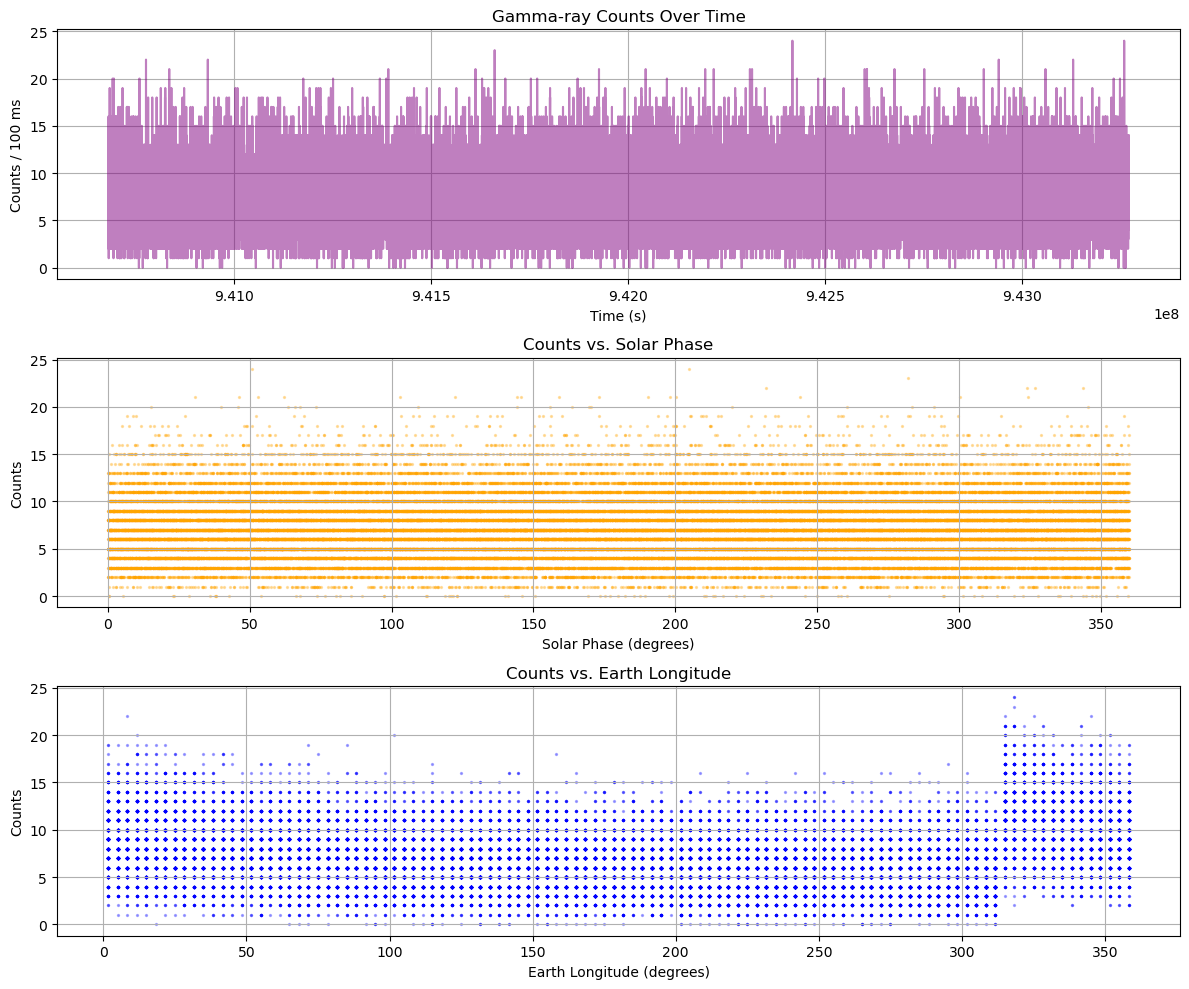

In [11]:
step = 500    # plotting only every 500th reading, so the graph dpesnt get too crowded

plt.figure(figsize=(12, 10))

plt.subplot(3, 1, 1)
plt.plot(time[::step], counts[::step], alpha=0.5, color='purple')
plt.xlabel('Time (s)')
plt.ylabel('Counts / 100 ms')
plt.title('Gamma-ray Counts Over Time')
plt.grid(True)

plt.subplot(3, 1, 2)
plt.scatter(solar_phase[::step], counts[::step], alpha=0.3, s=2, color='orange')
plt.xlabel('Solar Phase (degrees)')
plt.ylabel('Counts')
plt.title('Counts vs. Solar Phase')
plt.grid(True)

plt.subplot(3, 1, 3)
plt.scatter(earth_long[::step], counts[::step], alpha=0.3, s=2, color='blue')
plt.xlabel('Earth Longitude (degrees)')
plt.ylabel('Counts')
plt.title('Counts vs. Earth Longitude')
plt.grid(True)

plt.tight_layout()
plt.show()


### Discussion of data:
Looking at the plots, there are a few data anomalies that I see. There is quite a bit of noise in the second plot of Solar Phase vs. Counts.  This could be caused by stray gamma rays from the sun contaminating the data. Additionally, after the Earth longitude reaches about 315 degrees, there is a sharp increases of the plot ranges of the gamma ray counts.

I'll explore this more by making a 2d histogram of where the particle counts are most common for different solar phases and Earth longitudes.  

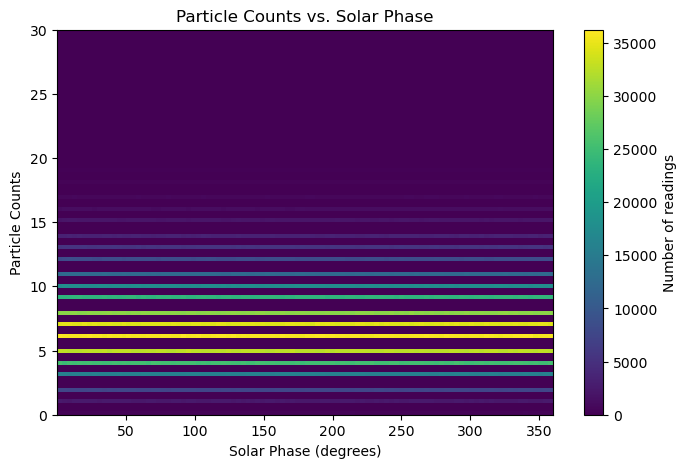

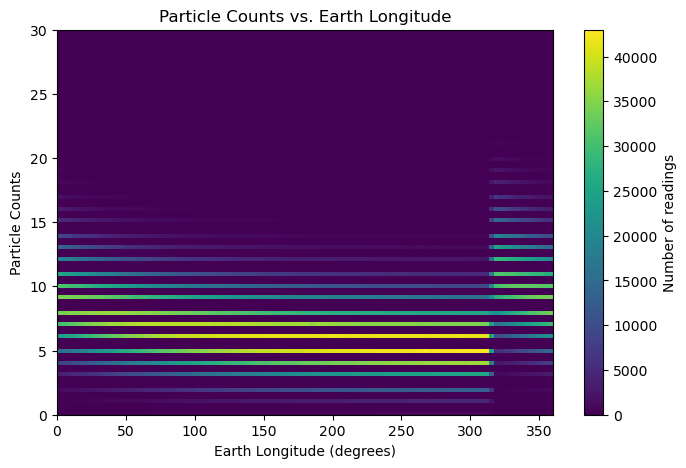

In [12]:
# Counts vs. solar phase
plt.figure(figsize=(8,5))
plt.hist2d(solar_phase, counts, bins=100)
plt.colorbar(label='Number of readings')
plt.xlabel('Solar Phase (degrees)')
plt.ylabel('Particle Counts')
plt.title('Particle Counts vs. Solar Phase')
plt.show()

# Counts vs. Earth longitude
plt.figure(figsize=(8,5))
plt.hist2d(earth_long, counts, bins=100)
plt.colorbar(label='Number of readings')
plt.xlabel('Earth Longitude (degrees)')
plt.ylabel('Particle Counts')
plt.title('Particle Counts vs. Earth Longitude')
plt.show()

The 2d histogram of solar phase vs. particle counts shows horizontal bands across nearly the entire solar phase range (0–360 degrees), which tells us that particle counts appear at similar levels across the different solar phases. There does not appear to be a strong relationship between solar phase and particle counts based on this plot. However, there is defintely something going on with the earth longitude.

Looking at the earth longitude plot again:

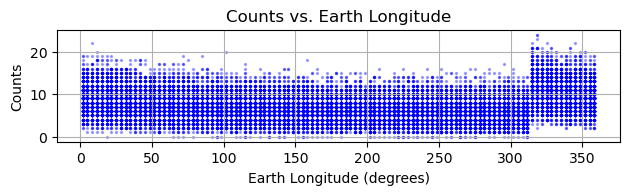

In [13]:
plt.subplot(3, 1, 3)
plt.scatter(earth_long[::step], counts[::step], alpha=0.3, s=2, color='blue')
plt.xlabel('Earth Longitude (degrees)')
plt.ylabel('Counts')
plt.title('Counts vs. Earth Longitude')
plt.grid(True)

plt.tight_layout()
plt.show()

I'll try measuring the background at different longitudes (10 degree longitude intervals) to see if I can estimate the background as a function of longitude.


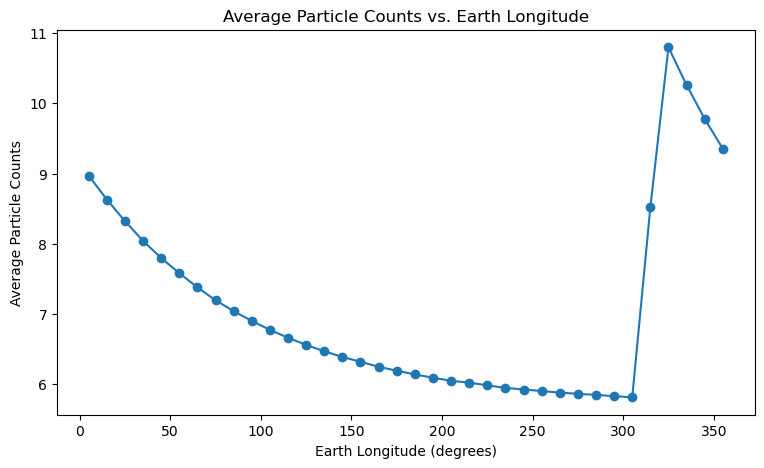

In [14]:
# dividing longitude into 10-degree intervals
longitude_bins = np.arange(0, 361, 10)

average_counts = []

for i in range(len(longitude_bins) - 1):
    selected = (earth_long >= longitude_bins[i]) & (earth_long < longitude_bins[i+1])
    average_counts.append(np.mean(counts[selected]))

longitude_centers = (longitude_bins[:-1] + longitude_bins[1:]) / 2

plt.figure(figsize=(9,5))
plt.plot(longitude_centers, average_counts, 'o-')
plt.xlabel('Earth Longitude (degrees)')
plt.ylabel('Average Particle Counts')
plt.title('Average Particle Counts vs. Earth Longitude')
plt.show()

### Average Particle Counts vs. Earth Longitude


The plot shows a gradual decrease in average particle counts from approximately 9 counts near 0 degrees to approximately 5.8 counts near 310 degrees. There is also a sharp increase around 315 degrees.

## How I plan to build a background pdf ()
My first idea was that, since this is counting discrete pieces of data, a Poisson distribution would be the best fit. However, this would not make sense since the average count changes quite a lot depending on the satellites position in its orbit in the plot above.

Therefore my plan to build the pdf is to look at how the mean of the distribution changes and I'll use that to construct a pdf.

To see what the general background looks like before building a background pdf, I'll also make a histogram of all the particle counts:






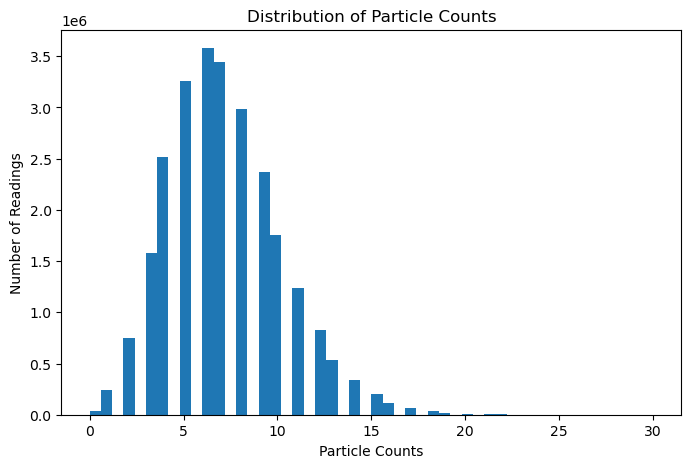

Mean counts: 7.09730524315952
Standard deviation: 3.032770718763134


In [15]:
plt.figure(figsize=(8,5))
plt.hist(counts, bins=50)
plt.xlabel('Particle Counts')
plt.ylabel('Number of Readings')
plt.title('Distribution of Particle Counts')
plt.show()

print('Mean counts:', np.mean(counts))
print('Standard deviation:', np.std(counts))

Looking at this plot, most readings have around 5–8 particle counts, and the distribution is slightly skewed to the right. The mean is 7.097 and the standard deviation is 3.033, but this is the average across the entire dataset since the background is changing with time. This gives an initial estimate of the overall background level.

# Part 2: The background is not consistent across the dataset. Find and describe as accurately as you can how the background changes.

The mean hourly counts, and the max and min of the hourly averages:

In [16]:
# Each reading is separated by 0.1 seconds so 36,000 readings =1 hour

group_size = 36000

average_time = []
average_counts_time = []

for i in range(0, len(time) - group_size, group_size):
    average_time.append(np.mean(time[i:i+group_size]))
    average_counts_time.append(np.mean(counts[i:i+group_size]))

average_time = np.array(average_time)
average_counts_time = np.array(average_counts_time)


print('Mean hourly counts:', np.mean(average_counts_time))
print('Minimum hourly average:', np.min(average_counts_time))
print('Maximum hourly average:', np.max(average_counts_time))

Mean hourly counts: 7.097305054012346
Minimum hourly average: 6.395444444444444
Maximum hourly average: 7.68725


Now a daily average plot:

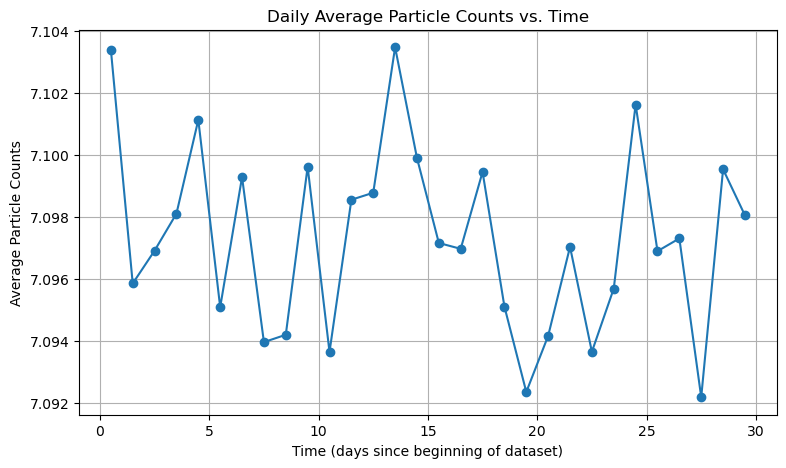

Mean daily counts: 7.097305054012344
Minimum daily average: 7.092195601851852
Maximum daily average: 7.103465277777778


In [17]:
# Each reading is separated by 0.1 seconds
# 864,000 readings = 1 day

group_size = 864000

daily_time = []
daily_counts = []

for i in range(0, len(time) - group_size, group_size):
    daily_time.append(np.mean(time[i:i+group_size]))
    daily_counts.append(np.mean(counts[i:i+group_size]))

daily_time = np.array(daily_time)
daily_counts = np.array(daily_counts)

# Convert time to days since the beginning
time_days = (daily_time - time[0]) / (60 * 60 * 24)

plt.figure(figsize=(9,5))
plt.plot(time_days, daily_counts, 'o-')
plt.xlabel('Time (days since beginning of dataset)')
plt.ylabel('Average Particle Counts')
plt.title('Daily Average Particle Counts vs. Time')
plt.grid()
plt.show()

print('Mean daily counts:', np.mean(daily_counts))
print('Minimum daily average:', np.min(daily_counts))
print('Maximum daily average:', np.max(daily_counts))



To investigate whether the background changes over longer periods, I calculated the average particle count for each day of the dataset. The resulting plot is pretty flat over the 30-day observation period.

The mean daily particle count is approximately 7.0973, with a minimum of 7.0922 and a maximum of 7.1035. This is a very small variation compared to the overall average.

 But that doesn't mean that the background is constant throughout the day... Since the satellite completes an orbit every 90 or so minutes, the background could still be changing throughout the day.

 I think that the background is changing with the satellite's orbital position, so I'll try to fold the time data over one orbit and model the changing Poisson mean.

# Part 3: Create a model for the background that includes time dependence, and explicitly compare your model to the data. How good is your model of the background?


Starting to develop the background plot:

Number of wraps: 480
Orbit period (seconds): 5400.0
Orbit period (minutes): 90.0


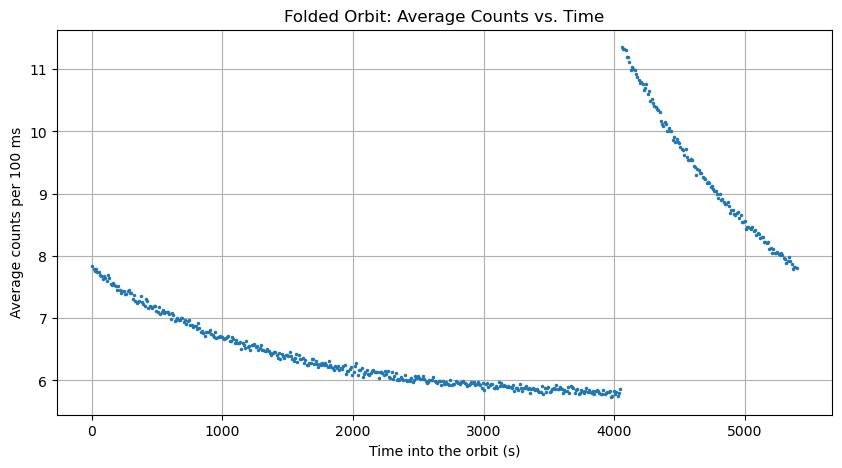

In [18]:
wrap_index = np.where(np.diff(earth_long) < -180)[0]

number_of_orbits = len(wrap_index) - 1

orbit_period = (
    time[wrap_index[-1]] - time[wrap_index[0]]
) / number_of_orbits

print('Number of wraps:', len(wrap_index))
print('Orbit period (seconds):', orbit_period)
print('Orbit period (minutes):', orbit_period / 60)
# time since the beginning of the current orbit
fold_time = (time - time[0]) % orbit_period

# the calculations were taking too long so i''ll only use every 10th reading
fold_s = fold_time[::10]
counts_s = counts[::10]

# divided the orbit into 10-second intervals
bin_width = 10
edges = np.arange(0, orbit_period + bin_width, bin_width)
bin_centers = (edges[:-1] + edges[1:]) / 2

average_counts = []

for i in range(len(edges) - 1):
    selected = (fold_s >= edges[i]) & (fold_s < edges[i+1])
    average_counts.append(np.mean(counts_s[selected]))

average_counts = np.array(average_counts)

plt.figure(figsize=(10, 5))
plt.plot(bin_centers, average_counts, '.', markersize=3)

plt.xlabel('Time into the orbit (s)')
plt.ylabel('Average counts per 100 ms')
plt.title('Folded Orbit: Average Counts vs. Time')
plt.grid()
plt.show()

This plot shows that the average background gradually decreases from 7.8 to 5.8 ad then increases to 11.3 count suddenly. It appears to be an exponential background model,

Jump occurs around: 4050.0 seconds into the orbit
C = 5.692397463031338 +/- 0.004116071879938146
A = 5.698833054490712 +/- 0.006739713269032368
tau = 1353.399984296893 +/- 4.050238350592103 seconds


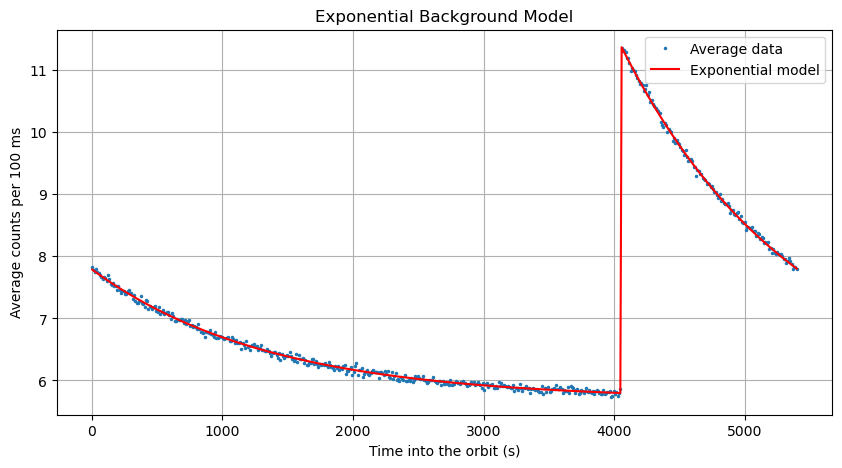

In [19]:
from scipy.optimize import curve_fit

#  the time of the largest increase in average counts
jump_bin = np.argmax(np.diff(average_counts)) + 1
t_jump = edges[jump_bin]

print('Jump occurs around:', t_jump, 'seconds into the orbit')

#  time since the most recent jump
time_since_jump = (bin_centers - t_jump) % orbit_period

#  bins immediately next to the jump
keep = (time_since_jump > 20) & (time_since_jump < orbit_period - 20)

# exponential background model
def background_model(t, C, A, tau):
    return C + A * np.exp(-t / tau)

#  guesses for C, A, and tau
guess = [np.min(average_counts), np.max(average_counts) - np.min(average_counts),orbit_period / 4
]


best, covariance = curve_fit(background_model, time_since_jump[keep],average_counts[keep],p0=guess, bounds=([0, 0, 1], [20, 20, 20000])
)

errors = np.sqrt(np.diag(covariance))

print('C =', best[0], '+/-', errors[0])
print('A =', best[1], '+/-', errors[1])
print('tau =', best[2], '+/-', errors[2], 'seconds')

#   fitted model
model_curve = background_model(time_since_jump, *best)

plt.figure(figsize=(10, 5))
plt.plot(bin_centers, average_counts, '.', markersize=3, label='Average data')
plt.plot(bin_centers, model_curve, 'r-', label='Exponential model')

plt.xlabel('Time into the orbit (s)')
plt.ylabel('Average counts per 100 ms')
plt.title('Exponential Background Model')
plt.legend()
plt.grid()
plt.show()

### Initial Background Model

I first determined the satellite's orbital period by finding where Earth longitude wraps from approximately 360 degrees back to 0 degrees. I found an orbital period of approximately 5,400 seconds, or 90 minutes.

I then folded the time data using the modulo operator so that measurements from different orbits could be compared at the same time within an orbit. I divided the folded orbit into 10-second intervals and calculated the average particle count in each interval.

The  plot shows that the average background gradually decreases from approximately 7.8 counts to 5.8 counts, followed by a sudden increase to approximately 11.3 counts. It then decreases again. This indicates that the background changes with orbital position and repeats approximately every 90 minutes.

I modeled the changing mean background with an exponential function:

$
\lambda(t)=C+Ae^{-t/\tau}
$



### How good is your model of the backgorund?
Comparing my model with the actual data:

In [20]:
# Predict the background for every tenth reading
since_jump_all = (fold_s - t_jump) % orbit_period
predicted = background_model(since_jump_all, *best)

# Calculate residuals
residuals = counts_s - predicted

# Divide residuals by expected Poisson standard deviation
pull = residuals / np.sqrt(predicted)

print('Mean residual:', np.mean(residuals))
print('RMSE of model:', np.sqrt(np.mean(residuals**2)))
print('RMSE using one overall mean:', np.std(counts_s))
print('Expected Poisson noise:', np.sqrt(np.mean(predicted)))
print('Mean pull:', np.mean(pull))
print('Standard deviation of pull:', np.std(pull))

Mean residual: -0.00045290272906666076
RMSE of model: 2.662723587848549
RMSE using one overall mean: 3.031910433319784
Expected Poisson noise: 2.663604276704342
Mean pull: -0.00014634602833002165
Standard deviation of pull: 0.9997271474580979


### Comparing the Background Model to the Data

To compare the model with the actual measurements, I calculated the actual counts minus the predicted background counts. The mean residual was -0.00045290272906666076, and the RMSE was 2.662723587848549. For comparison, using one overall mean produced an RMSE of 3.031910433319784. This shows that including the time dependence improved the background model.

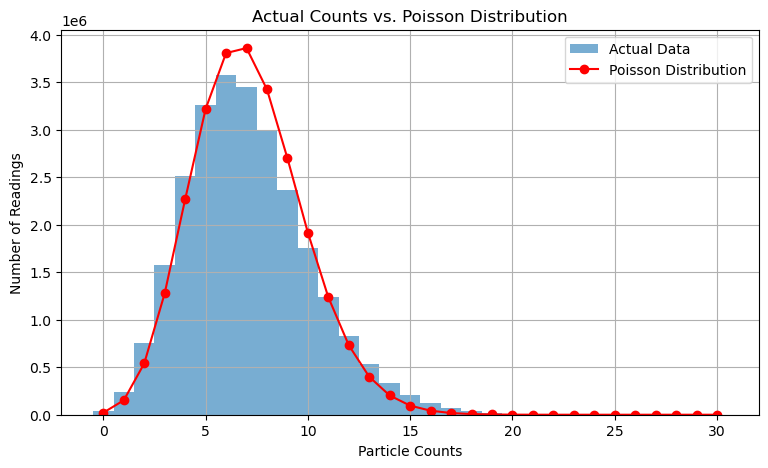

Actual standard deviation: 3.032770718763134
Expected Poisson standard deviation: 2.6640768087950315


In [21]:
#  the mean particle count
mean_counts = np.mean(counts)
k = np.arange(0, int(np.max(counts)) + 1)

#  expected Poisson frequencies
expected = len(counts) * stats.poisson.pmf(k, mean_counts)

#  the actual distribution
plt.figure(figsize=(9,5))

plt.hist(counts, bins=np.arange(-0.5, np.max(counts)+1.5, 1),
         label='Actual Data', alpha=0.6)

#  the expected Poisson distribution
plt.plot(k, expected, 'ro-', label='Poisson Distribution')

plt.xlabel('Particle Counts')
plt.ylabel('Number of Readings')
plt.title('Actual Counts vs. Poisson Distribution')
plt.legend()
plt.grid()
plt.show()

print('Actual standard deviation:', np.std(counts))
print('Expected Poisson standard deviation:', np.sqrt(mean_counts))

### Comparison with a Poisson Distribution

I compared the distribution of the measured particle counts with a Poisson distribution having the same mean. The mean particle count is approximately 7.0973, giving an expected Poisson standard deviation of approximately 2.6641.

However, the actual standard deviation is approximately 3.0328, which is larger than the expected Poisson standard deviation. So the measured data has more variation than a single Poisson distribution predicts.


# Part 4: Because the background varies, your discovery sensitivity threshold (how many particles you would need to see) also varies. What is the '5-sigma' threshold for a 100 millisecond GRB at different times?

In [22]:
prob_5sigma = stats.norm.sf(5)
print(f"Probability of 5-sigma: {prob_5sigma}")

Probability of 5-sigma: 2.866515718791933e-07



Constant threshold using overall mean: 25


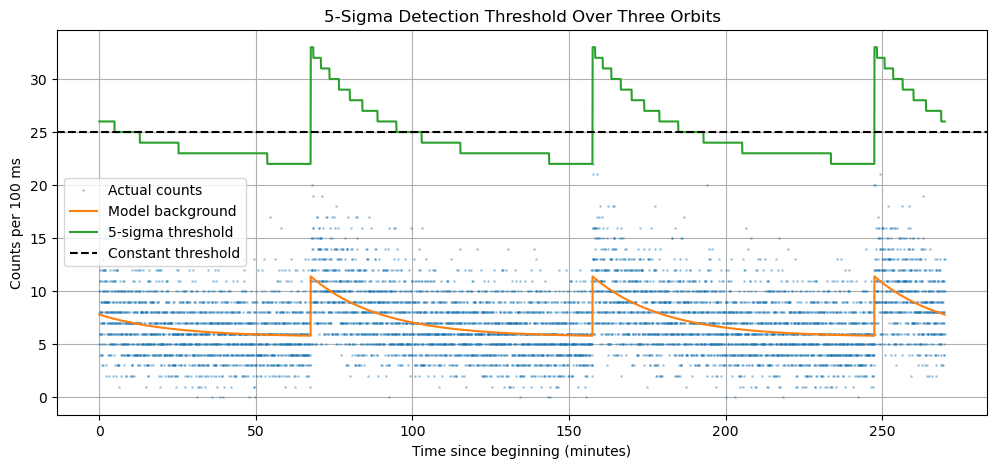

Lowest threshold in one orbit: 22
Highest threshold in one orbit: 33
Expected number of false 5-sigma readings: 7.430009029760262


In [23]:

def five_sigma_threshold(lam):
    return stats.poisson.isf(prob_5sigma, lam) + 1

# Compare with a constant threshold using the overall mean
constant_threshold = five_sigma_threshold(np.mean(counts))

print()
print('Constant threshold using overall mean:',
      int(constant_threshold))


    ## Now plotting this threshold over the 1st 3 orbits:

three_orbits = int(3 * orbit_period / 0.1)

#  every twentieth reading to make the plot easier to read
t_plot = time[:three_orbits:20] - time[0]
counts_plot = counts[:three_orbits:20]

#  time since the most recent jump
since_jump_plot = (t_plot - t_jump) % orbit_period

#  model background and threshold
mean_plot = background_model(since_jump_plot, *best)
threshold_plot = five_sigma_threshold(mean_plot)

plt.figure(figsize=(12, 5))
plt.plot(t_plot / 60, counts_plot, '.', markersize=2, alpha=0.3,label='Actual counts')
plt.plot(t_plot / 60, mean_plot,label='Model background')
plt.plot(t_plot / 60, threshold_plot,label='5-sigma threshold')
plt.axhline(constant_threshold,color='black',linestyle='--', label='Constant threshold')
plt.xlabel('Time since beginning (minutes)')
plt.ylabel('Counts per 100 ms')
plt.title('5-Sigma Detection Threshold Over Three Orbits')
plt.legend()
plt.grid()
plt.show()

orbit_thresholds = five_sigma_threshold(model_curve)

print('Lowest threshold in one orbit:', int(np.min(orbit_thresholds)))
print('Highest threshold in one orbit:', int(np.max(orbit_thresholds)))
print('Expected number of false 5-sigma readings:', len(counts) * prob_5sigma)

### 5-Sigma GRB Detection Threshold

The threshold varied from 22 to 33 counts per 100 milliseconds. This means that a GRB would need to produce a stronger signal during the high-background part of the orbit than during the low-background part. (By threshold here I mean the  total number of counts required, including the background, not the gamma ray burst counts alone)

# Part 5: What physical effect causes the changing background? (proposal)

After looking at the Wikipedia page for the Magnetosphere, (thanks Wikipedia! Link: https://en.wikipedia.org/wiki/Magnetosphere ), this paragraph in the History section seemed to be most relavant to the fluctuations seen in our data:

"*Beginning in the late 1940s, rockets were used to study cosmic rays. In 1958, Explorer 1, the first of the Explorer series of space missions, was launched to study the intensity of cosmic rays above the atmosphere and measure the fluctuations in this activity. This mission observed the existence of the Van Allen radiation belt (located in the inner region of Earth's magnetosphere), with the follow-up Explorer 3 later that year definitively proving its existence*"

Therefore my final proposed explanation is that the satellite is passing through the Van Allen Belt every orbit.

